# 00 — Brain metaphors and AI milestones

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/arvidl/brains-to-models/blob/main/code/notebooks/00_intro_timeline.ipynb)

## Why this notebook

When we say that an AI system sees, remembers or reasons, which comparison are we making? A useful answer distinguishes the problem being solved, the representation and procedure used to solve it, and the physical system doing the work. A computer can sort a list correctly without using a human sorting strategy. Two people can reach the same diagnosis through different evidence and reasoning. Shared performance invites a mechanism question; it does not answer it.

This opening notebook supplies two maps for the rest of the series. Marr's levels organize kinds of explanation. A timeline places selected brain metaphors alongside selected AI developments. Neither map is a fitted model. Their purpose is to help you formulate a comparison before interpreting the more technical notebooks.

### Learning goals

By the end, you should be able to:

1. Classify a claim about a brain or model as a claim about function, algorithm or implementation.
2. Explain why matching outputs leaves internal mechanisms underdetermined.
3. Use a historical example to generate a question, while distinguishing a dated event from an interpretation of its importance.
4. Propose evidence that could strengthen or weaken a brain–model analogy.

**Starting knowledge.** No machine-learning background is assumed. Read the printed tables before studying the figures. The code defines a catalogue, searches it and draws diagrams; there is no optimization, trained model or accuracy score.

Section numbers in the background readings refer to the [August background paper](https://github.com/arvidl/brains-to-models/blob/main/paper/background/august-perspective.pdf). For the current paper and 30-minute presentation, use the [paper](https://github.com/arvidl/brains-to-models/blob/main/paper/main.pdf) and the [slide-to-resource guide](https://github.com/arvidl/brains-to-models/blob/main/talk/resources.md).


## Concepts and two reading paths

<details open>
<summary><strong>For clinicians and neuroscientists</strong></summary>

**Computational theory** asks what problem a system solves and why that problem matters. In an imaging example, detecting an abnormality is a task; deciding how the detection will change care is part of its purpose. The task statement must specify inputs, outputs and conditions of success.

**Representation and algorithm** concern how information is encoded and transformed. An edge map, a diagnostic hypothesis and a vector of learned features are different representations. An algorithm describes operations on such representations. Equal diagnostic accuracy does not imply that a clinician and a model use the same evidence or procedure.

**Implementation** concerns the physical realization: neurons, synapses and bodily processes in one case; processors, memory and numerical operations in another. Different implementations can support similar functions. Conversely, a physical constraint such as energy use can shape which algorithms are feasible.

**Metaphor** suggests a way of organizing observations. **Mechanistic explanation** specifies components and interactions that can be tested. A clockwork or computer metaphor can prompt productive experiments without being a complete account of the mind.

Follow the notebook by asking what each diagram lets you conclude about an observable ability, and what extra observation would be needed to identify its mechanism.

</details>

<details>
<summary><strong>For mathematically inclined readers</strong></summary>

An input–output map $f:X\to Y$ does not specify a unique algorithm. Even if two systems agree on every tested pair $(x,f(x))$, their states, intermediate computations and behavior outside the tested domain may differ. Agreement on a finite dataset gives a weaker constraint still.

Marr's computational level specifies the problem and its rationale; the algorithmic level adds a representation and procedure; the implementational level specifies the physical realization. These are explanatory questions, rather than three independent modules of a network. Physical and algorithmic constraints can inform the problem formulation in return.

Treat a proposed analogy as a collection of hypotheses. An output comparison tests one hypothesis. Intervening on a representation or perturbing an implementation tests others. A similarity measure becomes informative only after its domain, normalization and relevant alternatives are stated.

The catalogue below is deterministic data. Its seed is retained for consistency with the series; it does not turn historical selection into a statistical sample. A missing event is an editorial omission, not evidence that an approach did not exist.

</details>


### Run in Colab or locally

Click **Open in Colab**, connect to a standard **CPU** runtime, and run the setup cell followed by the remaining cells in order (**Runtime → Run all**). The setup downloads the shared code and figure references from the public repository, installs the small numerical dependencies, and prints the checkout and Python version. It excludes the large presentation. No GPU, API key, patient data or Google Drive mount is needed.

Locally, use the environment in the [repository instructions](https://github.com/arvidl/brains-to-models/blob/main/README.md#run-the-notebooks) and select its Python kernel in Cursor or JupyterLab. The setup finds the repository and sets the working directory to `code/notebooks`, so exercise paths such as `%load ../solutions/...py` work in either environment.

Re-running setup reuses the existing checkout; it does not discard your runtime edits or pull new code automatically. For a fresh Colab checkout after repository updates, use **Runtime → Disconnect and delete runtime**, then reconnect and run again. Use **File → Save a copy in Drive** to retain notebook edits, and download generated files separately before the runtime ends. Saved output is a preview; rerunning produces the evidence for your session.


In [1]:
# Locate the shared code locally, or download a small checkout in Colab.
import os
from pathlib import Path
import subprocess
import sys

IN_COLAB = "google.colab" in sys.modules
REPO_URL = os.environ.get("BRAINSMODELS_REPO_URL",
                          "https://github.com/arvidl/brains-to-models.git")
if IN_COLAB:
    root = Path(os.environ.get("BRAINSMODELS_COLAB_ROOT",
                               "/content/brains-to-models"))
    if not (root / "code/src/brainsmodels").is_dir():
        # Sparse checkout keeps the large presentation out of the runtime.
        subprocess.check_call(["git", "clone", "--depth", "1", "--filter=blob:none",
                               "--sparse", "--branch", "main", REPO_URL, str(root)])
        subprocess.check_call(["git", "-C", str(root), "sparse-checkout", "set",
                               "code", "paper/figures"])
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                           "numpy>=1.26", "matplotlib>=3.8"])
else:
    here = Path.cwd().resolve()
    root = next((p for p in (here, *here.parents)
                 if (p / "pyproject.toml").is_file()
                 and (p / "code/src/brainsmodels").is_dir()), None)
    if root is None:
        raise RuntimeError("Open this notebook inside a brains-to-models checkout, "
                           "or use its Open in Colab badge.")

src = str(root / "code/src")
if src not in sys.path:
    sys.path.insert(0, src)
# Keep relative exercise paths consistent in Colab, JupyterLab and Cursor.
os.chdir(root / "code/notebooks")
repo = ROOT = root
import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
print("Checkout:", root)
print("Python:", sys.version.split()[0], "| NumPy:", np.__version__)
# End of shared setup.

from brainsmodels.repro import DEFAULT_SEED, set_seed
from brainsmodels.marr_levels import (
    LEVELS,
    format_levels,
    render_paper_figure as render_marr_figure,
    write_figure as write_marr_figure,
)
from brainsmodels.timeline import (
    EVENTS,
    find_events,
    format_catalogue,
    format_event,
    in_year_range,
    render_paper_figure,
    write_figure,
)

SEED = set_seed(DEFAULT_SEED)
plt.rcParams.update({"figure.dpi": 120, "font.size": 10})
print("repo root:", root)
print("seed:", SEED)
print(f"{len(EVENTS)} events in the catalogue")

Matplotlib is building the font cache; this may take a moment.


Checkout: CHECKOUT
Python: 3.12.2 | NumPy: 2.5.2
repo root: CHECKOUT
seed: 7
20 events in the catalogue


## Three levels of description

Hold the task fixed when comparing purpose, representation and algorithm, and implementation. A match at one level does not establish a match at the others.

**Before running.** For one task, write down an input, an output and a success criterion before naming an implementation. In the printed table, compare one row across the brain and model columns, then move down a row. Explain which inference would be needed to move from similar outputs to a similar procedure. The context band is a prompt for further questions, rather than a fourth Marr level or a measured difference.


Marr's three levels (Vision, 1982, pp. 24–25).
Each row is a description of the same system — brain or machine.
The levels are only loosely coupled.

1  Computational theory   [this paper: function]
   What is computed, and why that mapping is appropriate.
   brain    Example task: infer an object's location. Specify the behavioral goal.
   machine  Example task: predict the next token. Specify the training objective.
   A shared objective is possible. It does not fix the rows below.

2  Representation and algorithm   [this paper: dynamics]
   Which internal variables, and how they are transformed.
   brain    Candidate codes and update mechanisms. Test them against neural measurements.
   machine  Tokens, embeddings and attention. Training updates differ from inference.
   The same representation can be updated by a different algorithm.

3  Hardware implementation   [this paper: architecture]
   How representation and algorithm are realized physically.
   brain    Neurons, synapses, s

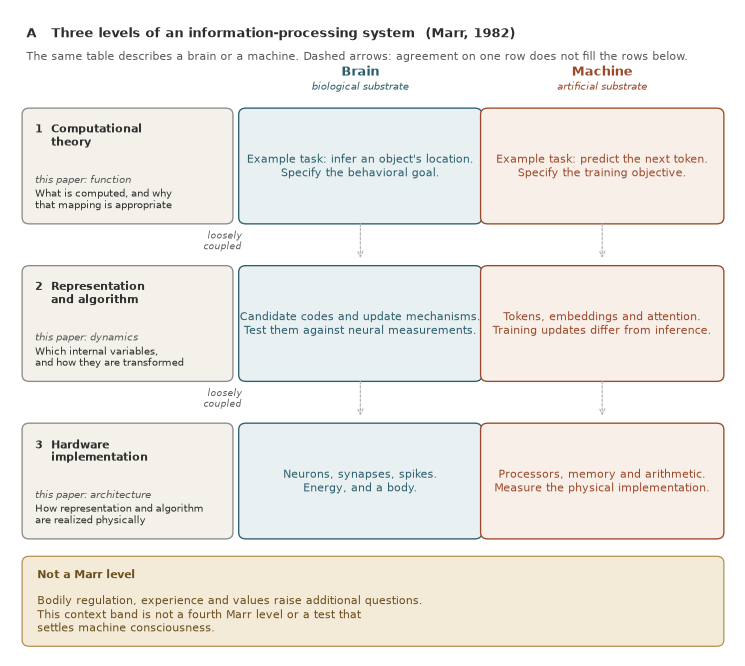

wrote CHECKOUT/paper/figures/marr_levels.pdf
wrote CHECKOUT/paper/figures/marr_levels.png


PosixPath('CHECKOUT/paper/figures/marr_levels.pdf')

In [2]:
print(format_levels())
print(f"{len(LEVELS)} Marr levels in the table")

fig = render_marr_figure()
plt.show()
write_marr_figure(root / "paper" / "figures")

## Read the timeline as a selection

Entries and filters make historical connections visible. Omitted architectures, researchers and scientific traditions limit any inference about the course of progress.

**Before running.** Before looking at dates, choose a claim you want the timeline to help investigate. If that claim concerns influence, chronology alone will not be enough: you would need writings or experiments showing the connection. If it concerns technical capability, a date label will not replace a stated task and result. Keep those two historical questions separate.


## The catalogue

`B` marks a brain-as metaphor, `A` marks an AI milestone, and `↔` marks an entry on both lanes. The paper figure uses a subset of these entries; the lookup cell can reach all of them.


In [3]:
print(format_catalogue())

20 events

  c. 1664  B  hydraulics              Descartes: animal spirits in pipes
     1748  B  clockwork               La Mettrie, L'Homme Machine
  c. 1870  B  telegraph               Helmholtz: nerve as a telegraph wire
     1943  ↔  logic gates             McCulloch & Pitts: neurons as propositions
     1948  B  feedback                Wiener: cybernetics, control by error
     1950  A  imitation game          Turing: can a machine pass as a person?
     1956  A  Dartmouth               The summer that named 'artificial intelligence'
     1958  B  the computer            von Neumann, The Computer and the Brain
     1958  A  perceptron              Rosenblatt: a learning machine from a simplified neuron
     1969  A  perceptrons             Minsky & Papert: what a single layer cannot do
     1982  ↔  Hopfield                Memories as attractors of an energy
     1986  B  PDP                     Rumelhart & McClelland: the mind as a parallel network
     1986  A  backprop        

## Timeline figure

Three older metaphors (Descartes, La Mettrie, Helmholtz) stand for the long unidirectional era. From 1943 the axis is linear. Dotted vertical lines mark years that belong to both lanes. The same call writes the PDF that the paper includes.


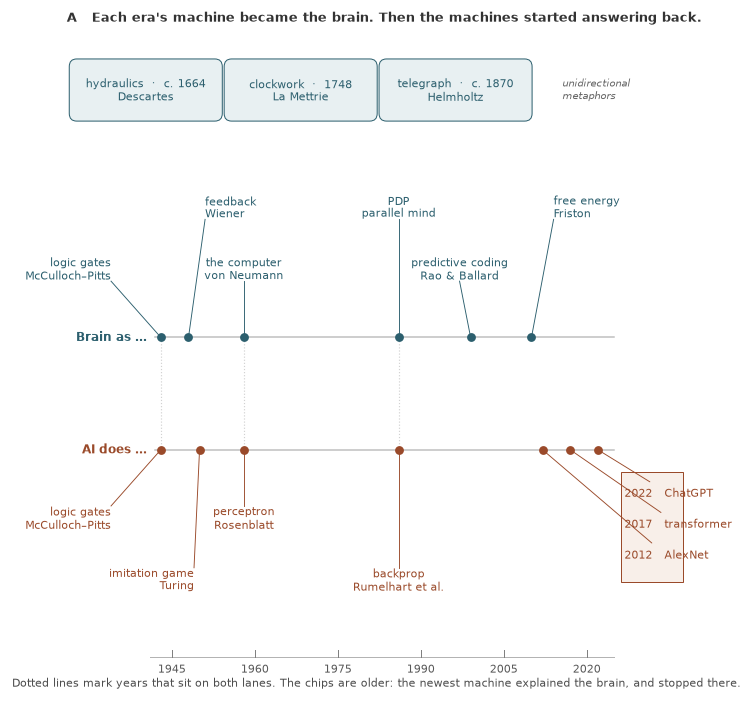

wrote CHECKOUT/paper/figures/intro_timeline.pdf
wrote CHECKOUT/paper/figures/intro_timeline.png


PosixPath('CHECKOUT/paper/figures/intro_timeline.pdf')

In [4]:
fig = render_paper_figure()
plt.show()
write_figure(root / "paper" / "figures")

## Look one up

Set `FOCUS` to a word in a title, a gloss, or a note — for example `hydraulics`, `perceptron`, `prediction`, `transformer`, `chatgpt`, or `both`. Set a year window to restrict the range. Re-run the cell.


In [5]:
FOCUS = "transformer"
YEAR_FROM, YEAR_TO = 1640, 2025

hits = in_year_range(YEAR_FROM, YEAR_TO, find_events(FOCUS))
print(f"FOCUS = {FOCUS!r}   years {YEAR_FROM}–{YEAR_TO}   {len(hits)} hit(s)\n")
if not hits:
    print("Nothing matched. Try hydraulics, perceptron, prediction, transformer, chatgpt.")
for ev in hits:
    print(format_event(ev))
    print()

FOCUS = 'transformer'   years 1640–2025   2 hit(s)

2017  transformer  [AI]
    Vaswani et al.: attention is all you need

A stack of causal (or bidirectional) attention layers, trained to predict the next token or to denoise a sequence. No recurrence required. Notebook 01 is this object at toy scale: one layer, four heads, next-character loss. The architecture of almost every foundation model since.

2020  GPT-3  [AI]
    In-context learning at scale

Brown et al. show that a large transformer trained on next-token prediction can do new tasks from a prompt, without weight updates. Competence looks like instruction-following; the objective has not changed. Scale makes the same score stranger.



## Work through one comparison

Take recognition of an abnormal region in an image. At the computational level, specify whether the output is a binary detection, a contour, a probability or a treatment recommendation. These tasks have different success criteria. At the algorithmic level, ask whether the system uses intensity, texture, spatial context, a learned feature or a site marker. At the implementational level, ask about memory, numerical precision, neural circuitry or energy constraints. Keeping the task fixed makes disagreements easier to interpret.

A useful comparison changes one aspect while preserving another. If a value-vector intervention changes a model's output while its attention weights stay fixed, a weight map is insufficient to reconstruct that output; notebook 10 demonstrates this exactly. If two segmenters receive the same images but different annotation policies, their contours may differ because the target changed; notebook 09 makes that distinction visible. These are more specific questions than whether a machine "sees like us."

### Reading the timeline carefully

The two lanes place selected metaphors and technical developments next to one another. Proximity in the drawing does not establish historical influence. A publication date does not mark a clean beginning, and a named milestone may depend on substantial earlier work. Use the search cell to find an entry, then consult its primary reference before making a historical claim.

Change `FOCUS` from `transformer` to `prediction`, and narrow `YEAR_FROM` and `YEAR_TO`. Explain what the filter selected and what it excluded. Then choose one absent tradition or development and describe how including it would alter the story. This is an exercise in making a selection explicit, rather than discovering a unique timeline of progress.

### Connect the maps to the other notebooks

Notebook 01 implements next-character prediction. Notebook 02 separates changing a model's inferred state from changing its weights. Notebook 02b compares acting with a known environment model against learning values through experience. Notebooks 05 and 12 examine state dynamics after a memory has been stored. Notebook 13 asks whether a numerical implementation satisfies its stated equations. Each example answers a different explanatory question.

For a discussion group, take one sentence from the paper and identify its level, the evidence offered and an alternative explanation. If it crosses levels, write the missing inference explicitly. Questions about experience, embodiment or human values can then be discussed with their assumptions visible. The contextual band in the levels figure raises such questions; it does not supply an experimental answer to them.

**Check your understanding.** Two classifiers have equal accuracy on one test set. Can you infer equal calibration, equal error cases, the same features, the same algorithm or the same physical substrate? None follows from the single aggregate score. State a separate measurement for each claim you would like to investigate.


### Questions for reflection

Use these questions to distinguish what the calculation shows from the assumptions and interpretations attached to it. Write an answer before consulting the instructor notes.


1. What does agreement at one of Marr’s levels establish, and what remains open?

2. Choose one task and describe it at all three levels.

3. What evidence would distinguish a useful brain metaphor from a proposed mechanism?

4. How do bodily regulation and experience relate to Marr’s framework?

5. What does filtering the timeline change?


### Further reading

These references provide background for the models and discussion. Distinguish primary experiments, reviews and commentary when using them as evidence. Section references follow the August background paper.

1. **Marr, D. (1982).** [*Vision: A Computational Investigation into the Human Representation and Processing of Visual Information*](https://hesperusisbosphorus.wordpress.com/wp-content/uploads/2015/10/david-marr-1982-vision-introduction.pdf). W. H. Freeman. Introduction, pp. 24–25 and Figure 1-4.
2. **Turing, A. M. (1950).** [*Computing Machinery and Intelligence*](https://redirect.cs.umbc.edu/courses/471/papers/turing.pdf). *Mind* 59(236), 433–460.
3. **Russell, S., and Norvig, P. (2021).** [*Artificial Intelligence: A Modern Approach*](https://aima.cs.berkeley.edu/). 4th ed., Pearson. Book site.
4. **Bommasani, R., et al. (2021).** [*On the Opportunities and Risks of Foundation Models*](https://arxiv.org/abs/2108.07258). arXiv:2108.07258.
5. **Doerig, A., et al. (2023).** [*The neuroconnectionist research programme*](https://konklab.fas.harvard.edu/Papers/Doerig_2023_NRN.pdf). *Nature Reviews Neuroscience* 24, 431–450.
6. **Butlin, P., Long, R., et al. (2023).** [*Consciousness in Artificial Intelligence: Insights from the Science of Consciousness*](https://arxiv.org/abs/2308.08708). arXiv:2308.08708.
